In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving adult_dataset.csv to adult_dataset.csv


In [3]:

df = pd.read_csv("adult_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Shape: (48842, 15)

First 5 Rows:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB

Missing Values:
age               2442
wo

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,46400.000000,45480,4.884200e+04,48842,48842.000000,48842,45485,48842,48842,48842,48842.000000,48842.000000,46400.000000,46137,48842
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,4
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,32220,NaN,15784,NaN,22379,5854,19716,41762,32650,NaN,NaN,NaN,41622,24720
mean,38.679116,NaN,1.896641e+05,NaN,10.078089,NaN,NaN,NaN,NaN,NaN,1079.067626,87.502314,40.448599,NaN,NaN
std,13.952954,NaN,1.056040e+05,NaN,2.570973,NaN,NaN,NaN,NaN,NaN,7452.019058,403.004552,12.646992,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.175505e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.781445e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.376420e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [5]:

# Make a copy of the original dataset
data = df.copy()

# Replace question marks with missing values
data = data.replace(r"^\s*\?\s*$", np.nan, regex=True)

# Remove income from clustering features
data = data.drop(columns=["income"])

# Identify numerical and categorical columns
num_cols = data.select_dtypes(
    include=["number"]
).columns

cat_cols = data.select_dtypes(
    include=["object", "category"]
).columns

# Fill numerical missing values with median
for col in num_cols:
    data[col] = data[col].fillna(
        data[col].median()
    )

# Fill categorical missing values with mode
for col in cat_cols:
    data[col] = data[col].fillna(
        data[col].mode()[0]
    )

print("Missing values after cleaning:")
print(data.isnull().sum())

print("Cleaned dataset shape:", data.shape)

Missing values after cleaning:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
dtype: int64
Cleaned dataset shape: (48842, 14)


In [6]:

# Detect and treat outliers using IQR method

data_clean = data.copy()

# Selected numerical columns
outlier_cols = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

for col in outlier_cols:
    Q1 = data_clean[col].quantile(0.25)
    Q3 = data_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    # Skip columns where IQR is zero
    if IQR == 0:
        print(f"{col}: IQR is zero; no capping applied")
        continue

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (data_clean[col] < lower) |
        (data_clean[col] > upper)
    ).sum()

    print(f"{col}: {outliers} outliers")

    data_clean[col] = data_clean[col].clip(
        lower=lower,
        upper=upper
    )

print("\nOutlier treatment completed!")


age: 364 outliers
fnlwgt: 1453 outliers
education-num: 1794 outliers
capital-gain: IQR is zero; no capping applied
capital-loss: IQR is zero; no capping applied
hours-per-week: 12838 outliers

Outlier treatment completed!


In [7]:

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer

numerical_cols = data_clean.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = data_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_cols)
])

X_scaled = preprocessor.fit_transform(data_clean)

print("Preprocessing completed!")
print("Encoded dataset shape:", X_scaled.shape)


Preprocessing completed!
Encoded dataset shape: (48842, 105)


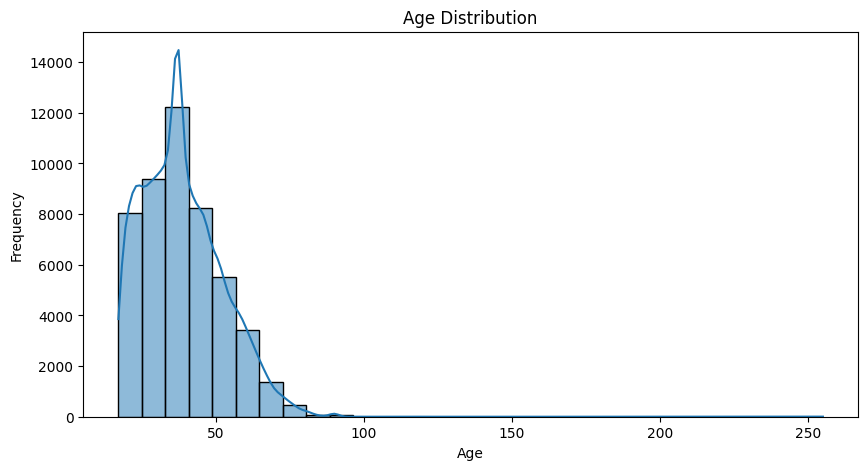

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data["age"],
    bins=30,
    kde=True
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


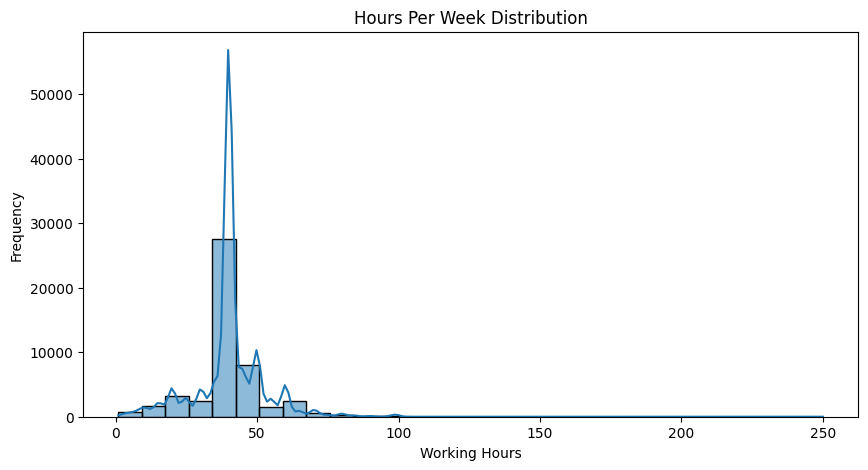

In [9]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data["hours-per-week"],
    bins=30,
    kde=True
)

plt.title("Hours Per Week Distribution")
plt.xlabel("Working Hours")
plt.ylabel("Frequency")
plt.show()


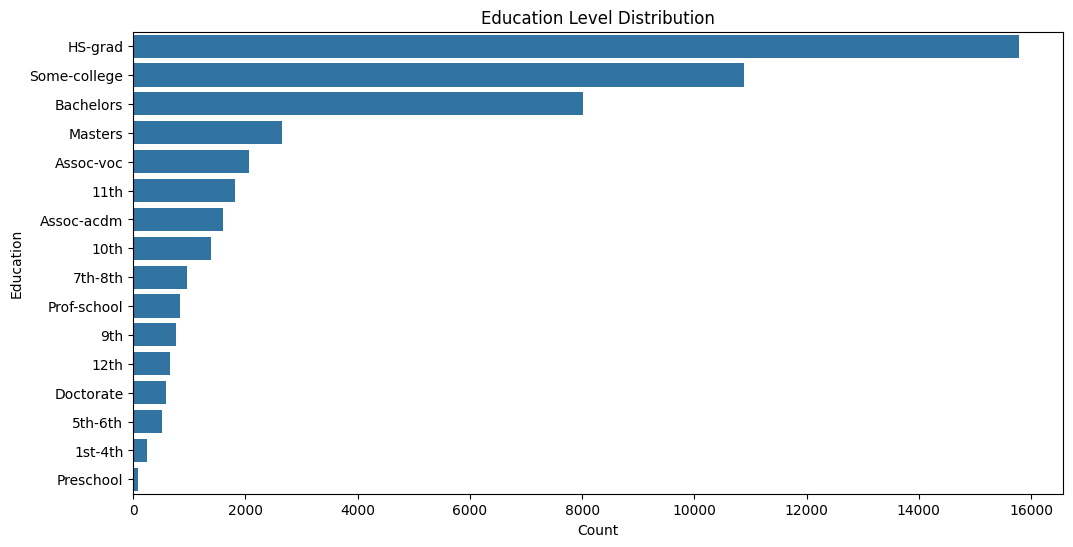

In [10]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=data,
    y="education",
    order=data["education"].value_counts().index
)

plt.title("Education Level Distribution")
plt.xlabel("Count")
plt.ylabel("Education")
plt.show()


In [11]:

print("Capital Gain Skewness:",
      data["capital-gain"].skew())

print("Capital Loss Skewness:",
      data["capital-loss"].skew())


Capital Gain Skewness: 11.894658996587946
Capital Loss Skewness: 4.569808857738485


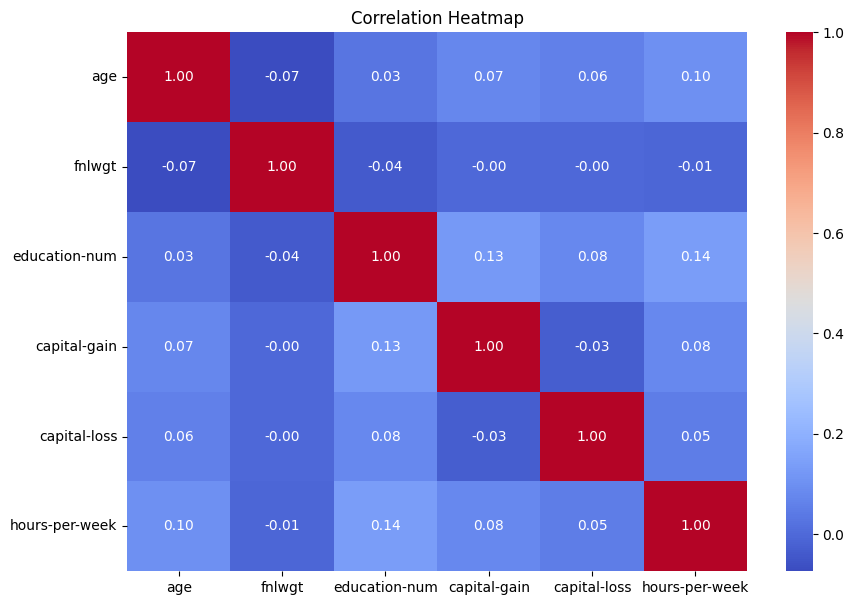

In [12]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    data.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


In [13]:

data_clean.to_csv(
    "cleaned_adult_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


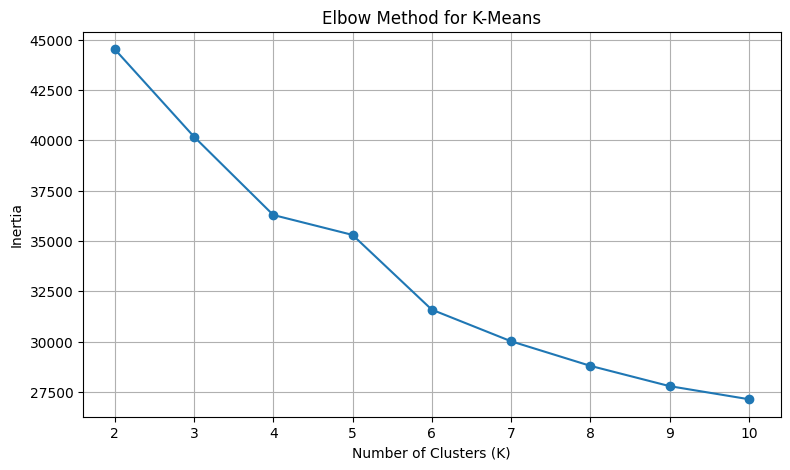

In [14]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Use the preprocessed dataset from Step 6
# Elbow analysis on a sample for faster execution

rng = np.random.default_rng(42)

sample_size = min(5000, len(X_scaled))

sample_indices = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled[sample_indices]

inertia = []

K_range = range(2, 11)

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_sample)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(K_range, inertia, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()


K=2, Silhouette Score=0.1079
K=3, Silhouette Score=0.1232
K=4, Silhouette Score=0.1296
K=5, Silhouette Score=0.1087
K=6, Silhouette Score=0.1237
K=7, Silhouette Score=0.1180
K=8, Silhouette Score=0.1164
K=9, Silhouette Score=0.1211
K=10, Silhouette Score=0.1155


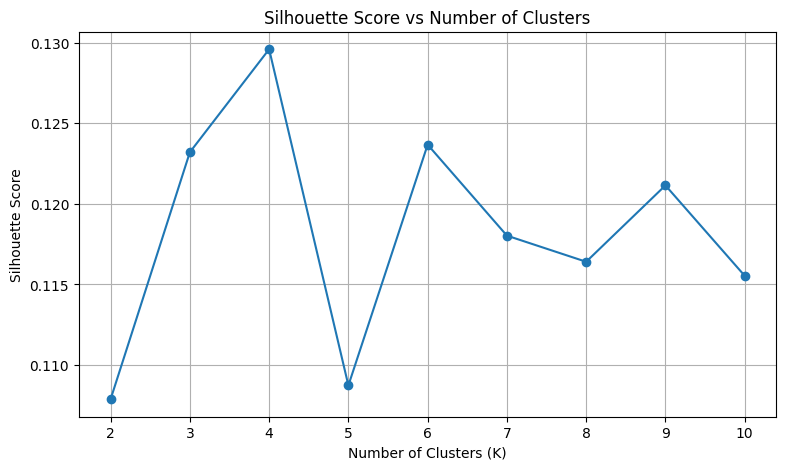

Best K based on silhouette: 4


In [15]:

from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels,
        sample_size=min(2000, len(X_sample)),
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

best_k = list(K_range)[
    np.argmax(silhouette_scores)
]

print("Best K based on silhouette:", best_k)


In [16]:

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(
    X_scaled
)

data_clean["KMeans_Cluster"] = kmeans_labels

print("K-Means Clustering Completed!")

print("\nCluster Distribution:")
print(
    data_clean["KMeans_Cluster"].value_counts()
    .sort_index()
)


K-Means Clustering Completed!

Cluster Distribution:
KMeans_Cluster
0    21808
1    24553
2      244
3     2237
Name: count, dtype: int64


In [17]:

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import adjusted_rand_score
import numpy as np
import matplotlib.pyplot as plt

# Sample records for hierarchical clustering
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_scaled),
    size=2000,
    replace=False
)

X_hier = X_scaled[sample_indices]

# Agglomerative clustering
agg_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_hier)

print("Agglomerative clustering completed!")

print("Cluster distribution:")
print(
    np.unique(agg_labels, return_counts=True)
)


Agglomerative clustering completed!
Cluster distribution:
(array([0, 1, 2, 3]), array([1305,  603,    9,   83]))


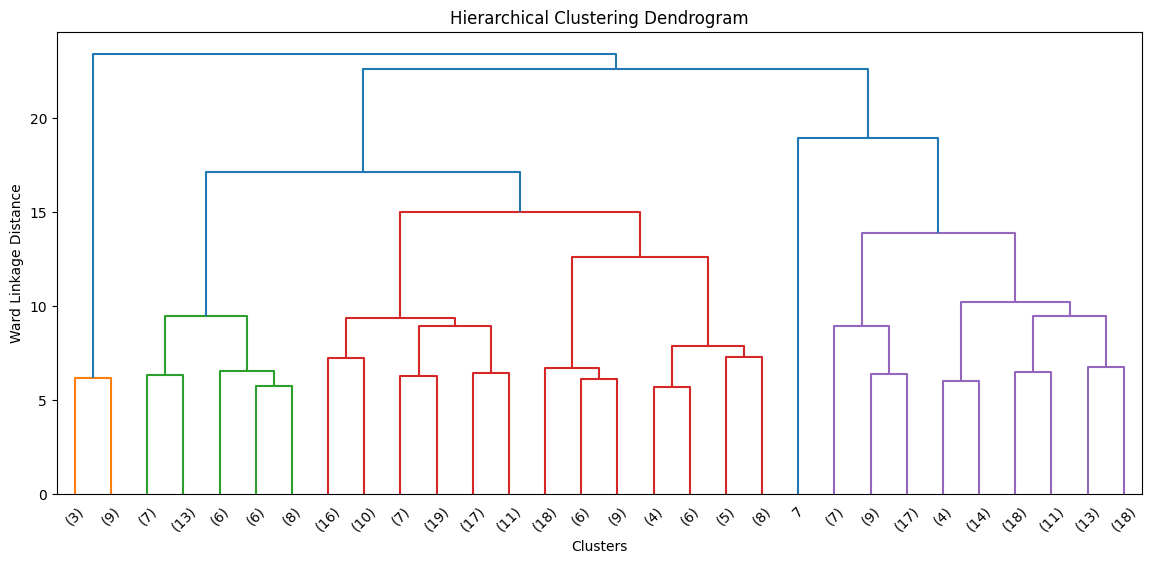

In [18]:

# Dendrogram on a smaller sample for readability
X_dendro = X_hier[:300]

linked = linkage(
    X_dendro,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Ward Linkage Distance")
plt.show()


In [19]:

# K-Means labels for the same sample
kmeans_sample_labels = kmeans_labels[sample_indices]

# Adjusted Rand Index measures agreement
ari = adjusted_rand_score(
    kmeans_sample_labels,
    agg_labels
)

print("Adjusted Rand Index:", round(ari, 4))

# Compare cluster distributions
comparison = pd.DataFrame({
    "KMeans": kmeans_sample_labels,
    "Agglomerative": agg_labels
})

print("\nCluster Comparison:")
display(pd.crosstab(
    comparison["KMeans"],
    comparison["Agglomerative"]
))


Adjusted Rand Index: 0.2845

Cluster Comparison:


Agglomerative,0,1,2,3
KMeans,,,,
0,859,69,0,0
1,446,534,0,0
2,0,0,9,0
3,0,0,0,83


Explained Variance Ratio:
[0.16326781 0.11396215]
Total Explained Variance: 27.72 %


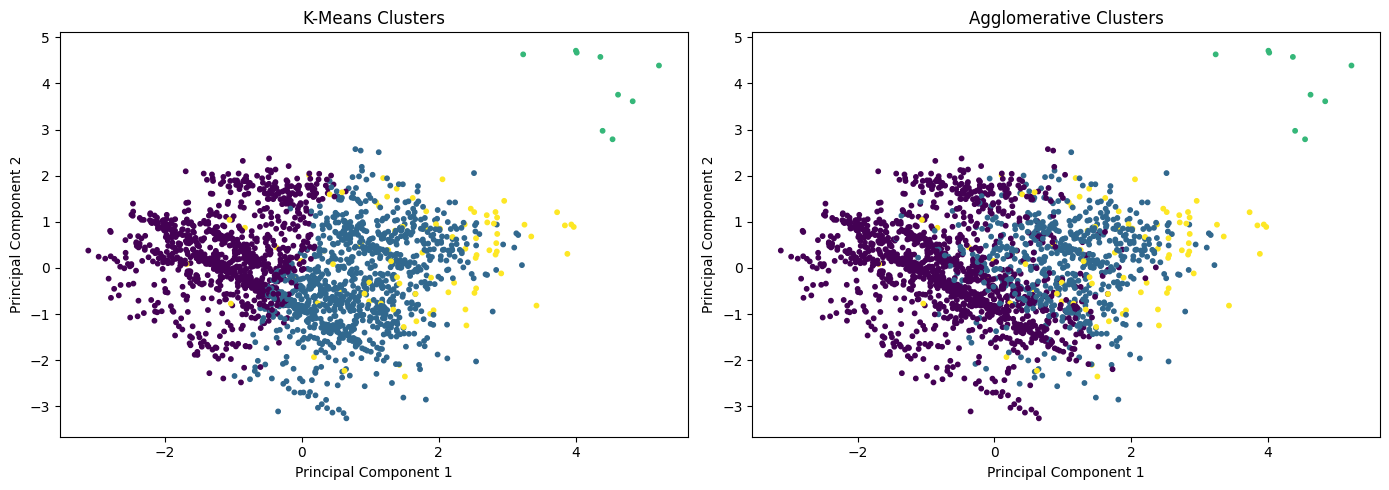

In [20]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_hier)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total Explained Variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_sample_labels,
    cmap="viridis",
    s=10
)

axes[0].set_title("K-Means Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=10
)

axes[1].set_title("Agglomerative Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()


In [21]:

# Compare numerical characteristics
numeric_profile = data_clean.groupby(
    "KMeans_Cluster"
)[[
    "age",
    "education-num",
    "hours-per-week",
    "capital-gain",
    "capital-loss"
]].mean().round(2)

print("Numerical Cluster Profile:")
display(numeric_profile)

# Compare categorical characteristics
categorical_profile = data_clean.groupby(
    "KMeans_Cluster"
)[[
    "workclass",
    "education",
    "occupation",
    "marital-status"
]].agg(lambda x: x.mode().iloc[0])

print("Categorical Cluster Profile:")
display(categorical_profile)


Numerical Cluster Profile:


,age,education-num,hours-per-week,capital-gain,capital-loss
KMeans_Cluster,,,,,
0,30.22,9.57,38.31,192.90,0.73
1,45.56,10.50,43.44,981.44,0.42
2,46.06,13.03,46.32,99999.00,0.00
3,41.58,11.03,42.68,0.00,1898.80


Categorical Cluster Profile:


,workclass,education,occupation,marital-status
KMeans_Cluster,,,,
0,Private,HS-grad,Prof-specialty,Never-married
1,Private,HS-grad,Prof-specialty,Married-civ-spouse
2,Private,Prof-school,Prof-specialty,Married-civ-spouse
3,Private,HS-grad,Prof-specialty,Married-civ-spouse


## Conclusion and Strategic Recommendations

### Case Study: Hidden Workforce Group Discovery Using Census Data

This case study applied unsupervised learning to identify hidden workforce segments using demographic and employment-related characteristics. The income variable was excluded from clustering to ensure that the discovered groups were based on the input features rather than predefined income categories.

### Key Findings

K-Means clustering identified four population segments:

1. **Cluster 0 – Younger Workforce:** Contains 21,808 individuals, with an average age of 30.22 years and relatively lower education levels.
2. **Cluster 1 – Established Workforce:** Contains 24,553 individuals, with an average age of 45.56 years and longer average working hours.
3. **Cluster 2 – High Capital-Gain Subgroup:** Contains 244 individuals, distinguished by exceptionally high reported capital gains.
4. **Cluster 3 – Capital-Loss Subgroup:** Contains 2,237 individuals, characterized by higher average reported capital losses.

### Strategic Recommendations

- Introduce vocational training and career development initiatives for younger workers.
- Provide leadership development and professional reskilling opportunities for established workers.
- Investigate the unusual capital-gain subgroup to understand whether extreme financial values are driving cluster formation.
- Consider targeted financial literacy and financial planning programs for groups with higher reported capital losses.
- Use additional demographic and employment analysis to refine workforce development policies.

### Final Conclusion

The clustering analysis demonstrates how unsupervised machine learning can reveal population segments without relying on predefined income labels.

However, the results are exploratory. Cluster 2 is particularly small and characterized by an extreme capital-gain value, suggesting that outliers may influence the clustering structure. Further validation is recommended before using these segments to inform real-world policy decisions.

In [22]:

# Save final clustered dataset
clustered_data = data_clean.copy()

clustered_data.to_csv(
    "workforce_clusters.csv",
    index=False
)

print("Clustered dataset saved successfully!")
print("Total records:", len(clustered_data))
print("Total clusters:",
      clustered_data["KMeans_Cluster"].nunique())


Clustered dataset saved successfully!
Total records: 48842
Total clusters: 4
